# SkyRun Inc. — Customer Retention and Cohort Analysis



## Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
DATA_FILE = "Skyrun dataset.csv"
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

## Data loading and quality checks

In [2]:
df = pd.read_csv(DATA_FILE, parse_dates=["InvoiceDate"])
print(df.shape)
df.info()

(541909, 8)
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   InvoiceDate  541909 non-null  datetime64[us]
 2   CustomerID   406829 non-null  float64       
 3   StockCode    541909 non-null  str           
 4   Description  541909 non-null  str           
 5   Quantity     541909 non-null  int64         
 6   UnitPrice    541909 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 33.1 MB


In [3]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Rows with Quantity <= 0 (returns/cancellations):", (df["Quantity"] <= 0).sum())
print("Rows with UnitPrice <= 0:", (df["UnitPrice"] <= 0).sum())

Missing values per column:
InvoiceNo           0
InvoiceDate         0
CustomerID     135080
StockCode           0
Description         0
Quantity            0
UnitPrice           0
Country             0
dtype: int64

Duplicate rows: 0
Rows with Quantity <= 0 (returns/cancellations): 0
Rows with UnitPrice <= 0: 0


In [4]:
rows_start = len(df)

# 1. Customers without an ID cannot be placed in a cohort
df = df.dropna(subset=["CustomerID"])

# 2. Exact duplicate rows
df = df.drop_duplicates()

# 3. Returns/cancellations and zero-price rows are not purchases
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()

# 4. Customer IDs as text (e.g. "12346"), not numbers like 12346.0
df["CustomerID"] = df["CustomerID"].astype(int).astype(str)

# 5. Revenue per line
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

print(f"Rows kept: {len(df):,} of {rows_start:,} ({len(df) / rows_start:.1%})")

Rows kept: 406,829 of 541,909 (75.1%)


In [5]:
df[["Quantity", "UnitPrice", "Revenue"]].describe().round(2)

,Quantity,UnitPrice,Revenue
count,406829.00,406829.00,406829.00
mean,50.48,50.48,2550.05
std,28.87,28.57,2211.43
min,1.00,1.00,1.00
25%,25.00,25.71,723.84
50%,50.00,50.43,1914.87
75%,75.00,75.17,3885.12
max,100.00,100.00,9999.00


### Can country and product category be used for segmentation?

The brief asks for segmentation by location and first-purchase category. These checks test whether each customer has one country and each product one category.

In [6]:
countries_per_customer = df.groupby("CustomerID")["Country"].nunique()
print("Countries in the data:", df["Country"].nunique())
print("Countries per customer:")
print(countries_per_customer.describe().round(1))

Countries in the data: 28
Countries per customer:
count    4372.0
mean       19.4
std         8.3
min         1.0
25%        13.0
50%        22.0
75%        27.0
max        28.0
Name: Country, dtype: float64


In [7]:
categories_per_product = df.groupby("StockCode")["Description"].nunique()
print("Categories in the data:", df["Description"].nunique())
print("Categories per product:")
print(categories_per_product.describe().round(1))

Categories in the data: 10
Categories per product:
count    9000.0
mean        9.9
std         0.3
min         7.0
25%        10.0
50%        10.0
75%        10.0
max        10.0
Name: Description, dtype: float64


**Result:** the typical customer appears in 22 of the 28 countries, and the typical product appears under all 10 categories. Neither column describes customers or products consistently, so geographic and category segmentation were not carried out. Segmentation is based on purchasing behaviour (Section 6).

## Overview of the year

In [8]:
print(f"Unique customers: {df['CustomerID'].nunique():,}")
print(f"Orders:           {df['InvoiceNo'].nunique():,}")
print(f"Products:         {df['StockCode'].nunique():,}")
print(f"Period:           {df['InvoiceDate'].min():%d %b %Y} to {df['InvoiceDate'].max():%d %b %Y}")

Unique customers: 4,372
Orders:           22,190
Products:         9,000
Period:           01 Dec 2024 to 09 Dec 2025


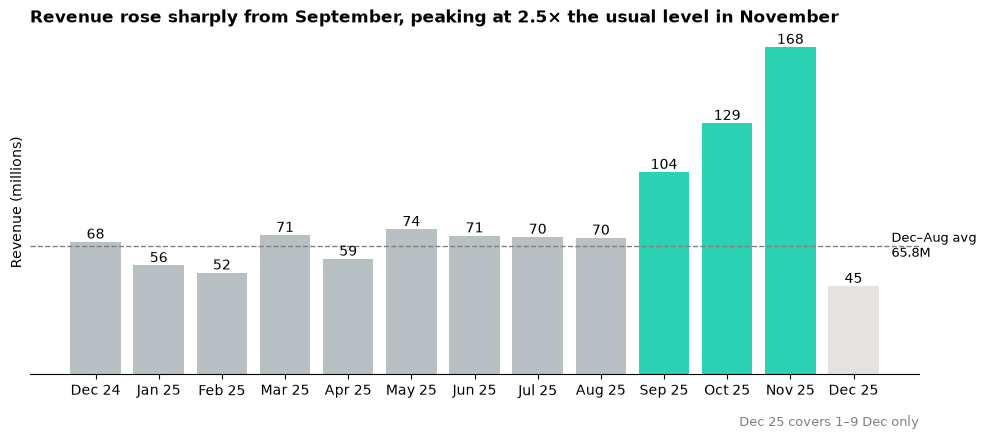

In [9]:
df["InvoiceMonth"] = df["InvoiceDate"].dt.to_period("M")

monthly = df.groupby("InvoiceMonth").agg(
    Revenue=("Revenue", "sum"),
    Customers=("CustomerID", "nunique"),
).reset_index()
monthly["InvoiceMonth"] = monthly["InvoiceMonth"].astype(str)

m = monthly.copy()
m["Revenue_m"] = m["Revenue"] / 1e6
labels = pd.PeriodIndex(m["InvoiceMonth"], freq="M").strftime("%b %y")
avg = m.loc[m["InvoiceMonth"] <= "2025-08", "Revenue_m"].mean()

colours = ["#2AD2B3" if mth in ["2025-09", "2025-10", "2025-11"] else
           "#E4E3E0" if mth == "2025-12" else "#B8C0C4" for mth in m["InvoiceMonth"]]

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(labels, m["Revenue_m"], color=colours)
ax.bar_label(bars, fmt="%.0f")
ax.axhline(avg, color="grey", linestyle="--", linewidth=1)
ax.text(len(m) - 0.4, avg, f"Dec–Aug avg\n{avg:.1f}M", va="center", fontsize=9)
ax.set_title("Revenue rose sharply from September, peaking at 2.5× the usual level in November",
             loc="left", fontsize=12, fontweight="bold")
ax.set_ylabel("Revenue (millions)")
ax.annotate("Dec 25 covers 1–9 Dec only", xy=(1, -0.15), xycoords="axes fraction",
            ha="right", fontsize=9, color="grey")
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.set_yticks([])
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/monthly_revenue.png", dpi=200)
plt.show()

## Cohorts and retention

In [10]:
# Each customer's cohort = month of first purchase
df["CohortMonth"] = df.groupby("CustomerID")["InvoiceMonth"].transform("min")

# Months since first purchase (1 = the joining month)
year_diff = df["InvoiceMonth"].dt.year - df["CohortMonth"].dt.year
month_diff = df["InvoiceMonth"].dt.month - df["CohortMonth"].dt.month
df["CohortIndex"] = year_diff * 12 + month_diff + 1

# Exclude the partial final month (Dec 2025, 9 days) from retention
complete = df[df["InvoiceMonth"] < df["InvoiceMonth"].max()]

cohort_counts = (complete.groupby(["CohortMonth", "CohortIndex"])["CustomerID"]
                   .nunique().reset_index())
cohort_pivot = cohort_counts.pivot(index="CohortMonth", columns="CohortIndex",
                                   values="CustomerID")

cohort_size = cohort_pivot.iloc[:, 0]
retention = cohort_pivot.divide(cohort_size, axis=0)

cohort_size.astype(int).to_frame("New customers")

,New customers
CohortMonth,
2024-12,948
2025-01,421
2025-02,380
2025-03,440
2025-04,299
2025-05,279
2025-06,235
2025-07,191
2025-08,167


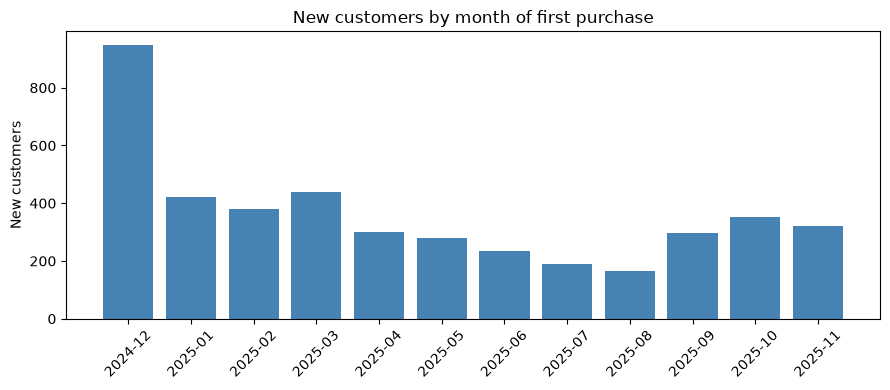

In [11]:
sizes = cohort_size.copy()
sizes.index = sizes.index.astype(str)

plt.figure(figsize=(9, 4))
plt.bar(sizes.index, sizes.values, color="steelblue")
plt.title("New customers by month of first purchase")
plt.ylabel("New customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/new_customers.png", dpi=200)
plt.show()

*The December 2024 cohort includes customers who were already buying before the data starts, so it is larger and retains better than later cohorts. It is excluded from cohort comparisons.*

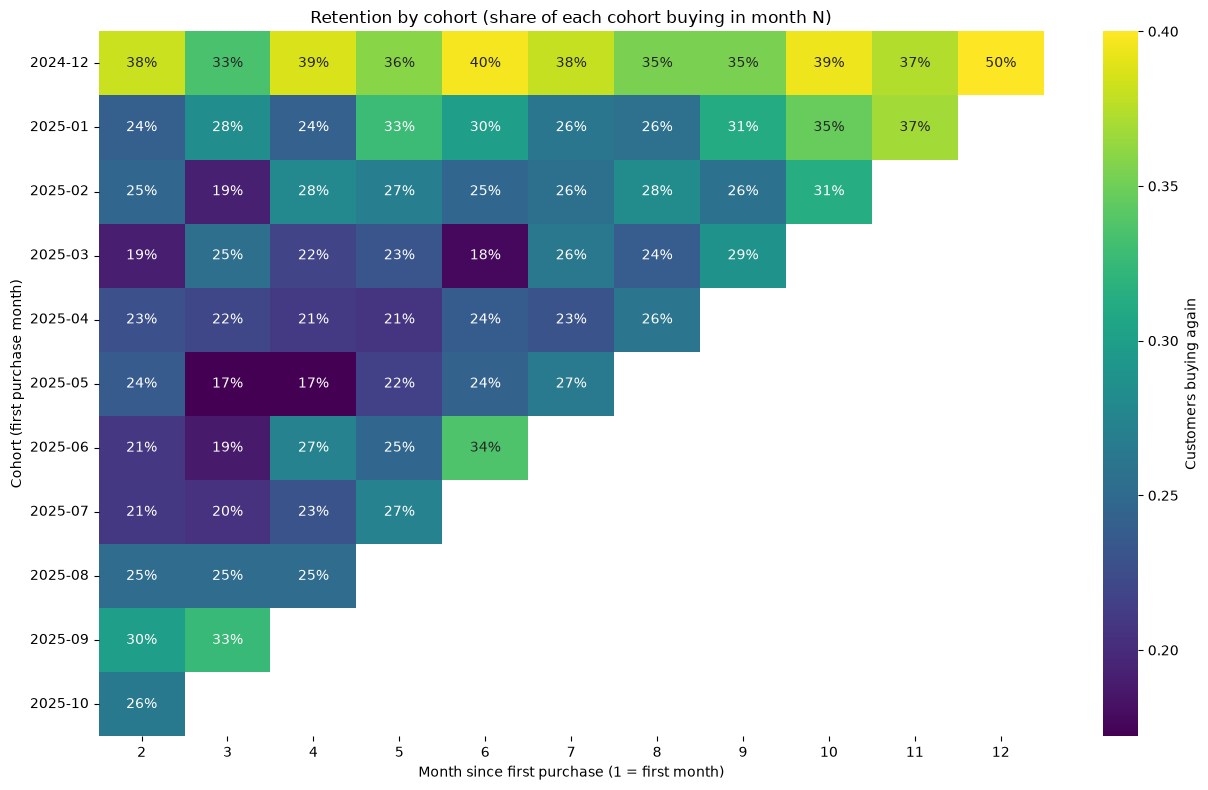

In [12]:
# Month 1 is always 100%, so the heatmap starts at month 2
plt.figure(figsize=(13, 8))
sns.heatmap(retention.iloc[:, 1:].dropna(how="all"), annot=True, fmt=".0%",
            cmap="viridis", vmax=0.4, cbar_kws={"label": "Customers buying again"})
plt.title("Retention by cohort (share of each cohort buying in month N)")
plt.xlabel("Month since first purchase (1 = first month)")
plt.ylabel("Cohort (first purchase month)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/retention_heatmap.png", dpi=200)
plt.show()

In [13]:
# Compare cohorts at the same age: month 2, 4 and 7
checkpoints = [c for c in [2, 4, 7] if c in retention.columns]
trend = (retention[checkpoints] * 100).round(1)
trend.columns = [f"Month {c} retention %" for c in checkpoints]
trend.index = trend.index.astype(str)
trend

,Month 2 retention %,Month 4 retention %,Month 7 retention %
CohortMonth,,,
2024-12,38.2,38.7,38.0
2025-01,24.0,24.2,26.1
2025-02,24.7,27.9,25.5
2025-03,19.1,21.8,26.4
2025-04,22.7,21.1,23.1
2025-05,23.7,17.2,26.5
2025-06,20.9,27.2,NaN
2025-07,20.9,23.0,NaN
2025-08,25.1,25.1,NaN


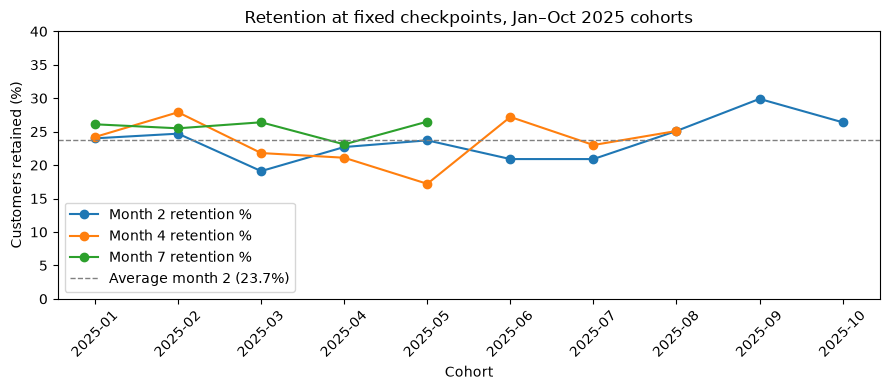

In [14]:
plot_trend = trend.drop(index="2024-12").dropna(how="all")
avg_m2 = plot_trend["Month 2 retention %"].mean()

fig, ax = plt.subplots(figsize=(9, 4))
for col in plot_trend.columns:
    ax.plot(plot_trend.index, plot_trend[col], marker="o", label=col)
ax.axhline(avg_m2, color="grey", linestyle="--", linewidth=1,
           label=f"Average month 2 ({avg_m2:.1f}%)")
ax.set(title="Retention at fixed checkpoints, Jan–Oct 2025 cohorts",
       ylabel="Customers retained (%)", xlabel="Cohort", ylim=(0, 40))
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="lower left")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/retention_checkpoints.png", dpi=200)
plt.show()

## Drop-off points and churn

In [15]:
# Average retention curve: where is the biggest drop?
avg_curve = retention.mean() * 100
drop = avg_curve.diff()
print("Average retention by month since first purchase (%):")
print(avg_curve.head(9).round(1).to_string())
print(f"\nLargest single fall: between month {drop.idxmin() - 1} and month {drop.idxmin()} "
      f"({drop.min():.1f} percentage points)")

Average retention by month since first purchase (%):
CohortIndex
1    100.0
2     25.1
3     24.2
4     25.1
5     26.6
6     27.7
7     27.6
8     27.8
9     30.3

Largest single fall: between month 1 and month 2 (-74.9 percentage points)


*Later months (9 onwards) are left out because only the oldest cohorts reach them, which makes the average unreliable.*

In [16]:
orders = df.groupby("CustomerID")["InvoiceNo"].nunique()

print(f"One-time buyers:      {(orders == 1).mean():.1%}")
print(f"Repeat purchase rate: {(orders > 1).mean():.1%}")

order_dist = orders.clip(upper=10).value_counts().sort_index()
order_dist.index = [str(i) if i < 10 else "10+" for i in order_dist.index]
order_dist.to_frame("Customers")

One-time buyers:      30.0%
Repeat purchase rate: 70.0%


,Customers
1,1313
2,817
3,490
4,377
5,288
6,196
7,157
8,117
9,80
10+,537


In [17]:
# Fair comparison: did customers buy again within their first 3 months (CohortIndex 2-4)?
# Only cohorts with 3 full months after joining (up to August 2025) are shown.
returners = complete[complete["CohortIndex"].between(2, 4)]["CustomerID"].unique()

customers = df.groupby("CustomerID")["CohortMonth"].first().to_frame()
customers["Returned"] = customers.index.isin(returners)

returned_3m = (customers.groupby("CohortMonth")["Returned"].mean() * 100).round(1)
returned_3m.loc[:"2025-08"].to_frame("Returned within 3 months %")

,Returned within 3 months %
CohortMonth,
2024-12,60.2
2025-01,50.6
2025-02,49.5
2025-03,45.0
2025-04,46.5
2025-05,39.8
2025-06,45.1
2025-07,44.5
2025-08,49.7


In [18]:
# Days between first and second order
invoice_dates = (df.groupby(["CustomerID", "InvoiceNo"])["InvoiceDate"].min()
                   .reset_index().sort_values(["CustomerID", "InvoiceDate"]))
invoice_dates["order_number"] = invoice_dates.groupby("CustomerID").cumcount() + 1

first_two = invoice_dates[invoice_dates["order_number"] <= 2].pivot(
    index="CustomerID", columns="order_number", values="InvoiceDate").dropna()
gap_days = (first_two[2] - first_two[1]).dt.days

# Second orders on the same day are more likely split baskets than return visits
print(f"Second order on the same day: {(gap_days == 0).mean():.1%} (excluded)")
true_gaps = gap_days[gap_days > 0]

print(f"Repeat buyers (excluding same-day): {len(true_gaps):,}")
print(f"Median days to second purchase: {true_gaps.median():.0f}")
print(f"Within 30 days: {(true_gaps <= 30).mean():.1%}")
print(f"Within 90 days: {(true_gaps <= 90).mean():.1%}")

Second order on the same day: 10.9% (excluded)
Repeat buyers (excluding same-day): 2,726
Median days to second purchase: 41
Within 30 days: 41.7%
Within 90 days: 71.1%


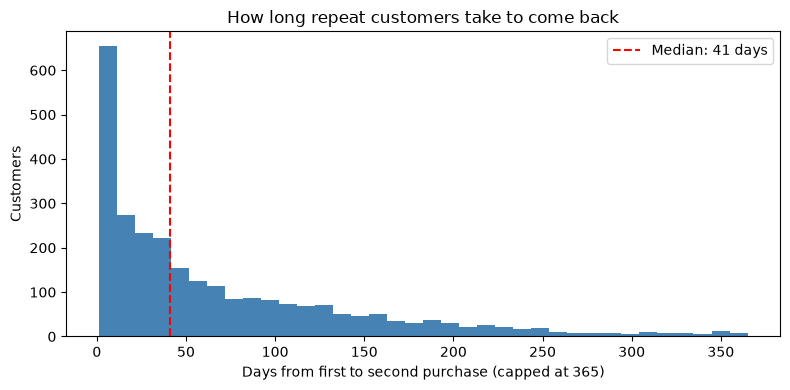

In [19]:
plt.figure(figsize=(8, 4))
plt.hist(true_gaps.clip(upper=365), bins=36, color="steelblue")
plt.axvline(true_gaps.median(), color="red", linestyle="--",
            label=f"Median: {true_gaps.median():.0f} days")
plt.xlabel("Days from first to second purchase (capped at 365)")
plt.ylabel("Customers")
plt.title("How long repeat customers take to come back")
plt.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/days_to_second_purchase.png", dpi=200)
plt.show()

In [20]:
# Churn threshold: the time within which 90% of repeat buyers return
churn_threshold = int(true_gaps.quantile(0.9))
print(f"90% of repeat buyers return within {churn_threshold} days.")

last_purchase = df.groupby("CustomerID")["InvoiceDate"].max()
days_since = (df["InvoiceDate"].max() - last_purchase).dt.days

status = pd.cut(days_since, bins=[-1, 90, churn_threshold, 1000],
                labels=["Active", "At risk", "Churned"])
status.value_counts(sort=False).rename_axis("Status").to_frame("Customers").assign(
    Share=lambda t: (t["Customers"] / t["Customers"].sum() * 100).round(1))

90% of repeat buyers return within 182 days.


,Customers,Share
Status,,
Active,2922,66.8
At risk,597,13.7
Churned,853,19.5


## Customer segmentation (RFM + K-Means)

In [21]:
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    recency_days=("InvoiceDate", lambda x: (reference_date - x.max()).days),
    frequency=("InvoiceNo", "nunique"),
    monetary=("Revenue", "sum"),
).reset_index()

rfm.describe().round(1)

,recency_days,frequency,monetary
count,4372.0,4372.0,4372.0
mean,92.0,5.1,237290.9
std,100.8,9.3,594460.3
min,1.0,1.0,17.4
25%,17.0,1.0,43508.9
50%,50.0,3.0,106692.5
75%,143.0,5.0,259915.4
max,374.0,248.0,20383830.6


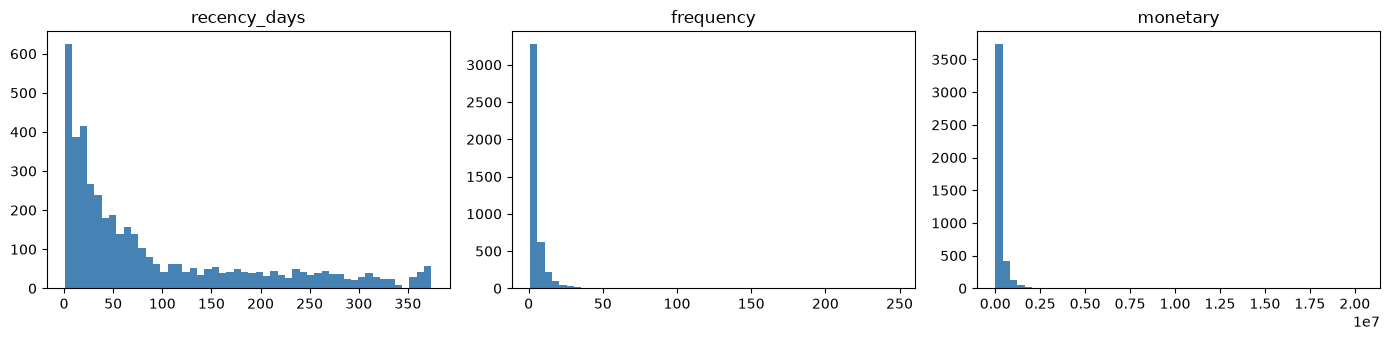

Correlation between frequency and monetary: 0.78


In [22]:
# Frequency and monetary are heavily right-skewed, so they are log-transformed
# before scaling; otherwise a few very large customers dominate the clusters.
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["recency_days", "frequency", "monetary"]):
    ax.hist(rfm[col], bins=50, color="steelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

print("Correlation between frequency and monetary:",
      round(rfm["frequency"].corr(rfm["monetary"]), 2))

X = np.log1p(rfm[["recency_days", "frequency", "monetary"]])
X_scaled = StandardScaler().fit_transform(X)

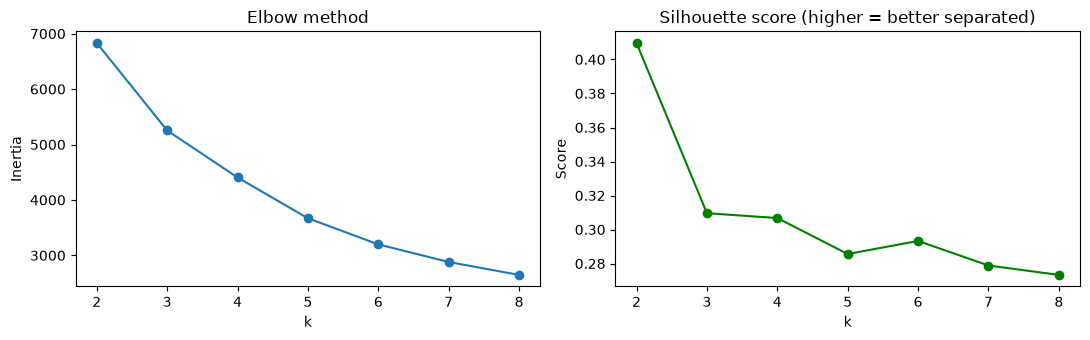

,k,silhouette
0,2,0.410
1,3,0.310
2,4,0.307
3,5,0.286
4,6,0.293
5,7,0.279
6,8,0.273


In [23]:
# Choose k using the elbow method and silhouette scores
ks = range(2, 9)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_scaled)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(ks, inertia, marker="o")
axes[0].set(title="Elbow method", xlabel="k", ylabel="Inertia")
axes[1].plot(ks, silhouette, marker="o", color="green")
axes[1].set(title="Silhouette score (higher = better separated)", xlabel="k", ylabel="Score")
plt.tight_layout()
plt.show()

pd.DataFrame({"k": list(ks), "silhouette": np.round(silhouette, 3)})

k = 4 was chosen: silhouette scores for k = 3 and k = 4 are almost identical, and four segments give more useful groups for targeting.

In [24]:
K = 4

final_model = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10).fit(X_scaled)
rfm["Cluster"] = final_model.labels_

cluster_profile = rfm.groupby("Cluster").agg(
    recency_days=("recency_days", "mean"),
    frequency=("frequency", "mean"),
    monetary=("monetary", "mean"),
    NumCustomers=("CustomerID", "count"),
).round(1)
cluster_profile["Share %"] = (cluster_profile["NumCustomers"] / len(rfm) * 100).round(1)
cluster_profile["Revenue share %"] = (
    rfm.groupby("Cluster")["monetary"].sum() / rfm["monetary"].sum() * 100).round(1)
cluster_profile.sort_values("monetary", ascending=False)

,recency_days,frequency,monetary,NumCustomers,Share %,Revenue share %
Cluster,,,,,,
1,10.8,15.7,750853.5,786,18.0,56.9
0,74.4,4.8,250363.1,1155,26.4,27.9
3,21.1,2.3,96598.2,909,20.8,8.5
2,189.8,1.5,46181.1,1522,34.8,6.8


In [25]:
# Cluster numbers are arbitrary: these names were matched to the profile table above.
# If the clusters change (different data or random state), re-check before reusing the names.
cluster_names = {
    0: "Regulars",
    1: "Champions",
    2: "Lost",
    3: "New / Promising",
}
cluster_profile["Segment"] = cluster_profile.index.map(cluster_names)
rfm["Segment"] = rfm["Cluster"].map(cluster_names)

(cluster_profile.sort_values("monetary", ascending=False).set_index("Segment")
    .rename(columns={
        "recency_days": "Days since last purchase",
        "frequency": "Orders",
        "monetary": "Spend",
        "NumCustomers": "Customers",
        "Share %": "% of customers",
        "Revenue share %": "% of revenue",
    })
    .round({"Days since last purchase": 0, "Spend": 0})
    .astype({"Days since last purchase": int, "Spend": int}))

,Days since last purchase,Orders,Spend,Customers,% of customers,% of revenue
Segment,,,,,,
Champions,11,15.7,750854,786,18.0,56.9
Regulars,74,4.8,250363,1155,26.4,27.9
New / Promising,21,2.3,96598,909,20.8,8.5
Lost,190,1.5,46181,1522,34.8,6.8


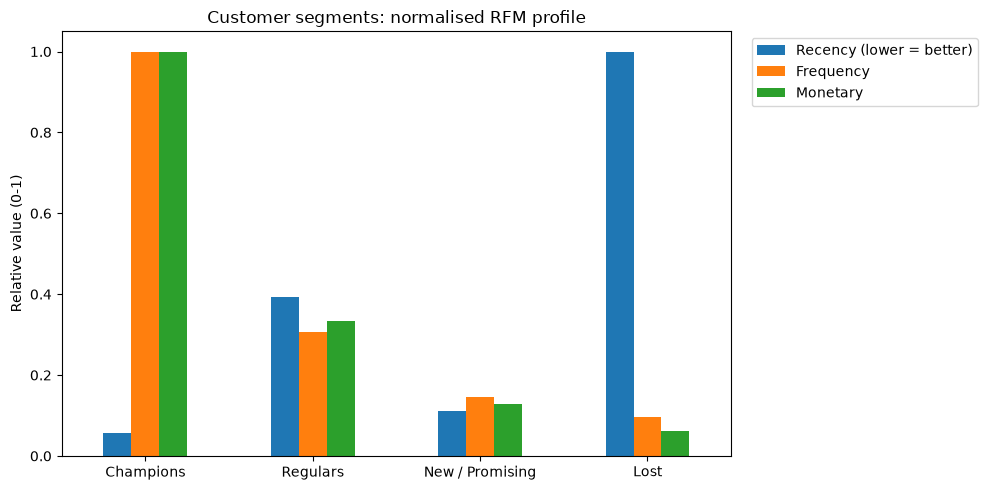

In [26]:
# Each measure scaled to its highest segment value; for recency, shorter is better
plot_df = (cluster_profile.sort_values("monetary", ascending=False)
           .set_index("Segment")[["recency_days", "frequency", "monetary"]])
plot_df = plot_df / plot_df.max()

plot_df.plot(kind="bar", figsize=(10, 5))
plt.title("Customer segments: normalised RFM profile")
plt.ylabel("Relative value (0-1)")
plt.xlabel("")
plt.xticks(rotation=0)
plt.legend(["Recency (lower = better)", "Frequency", "Monetary"],
           bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/rfm_segments.png", dpi=200)
plt.show()

## Customer value by cohort

In [27]:
cohort_value = df.groupby("CohortMonth").agg(
    Customers=("CustomerID", "nunique"),
    Revenue=("Revenue", "sum"),
    Orders=("InvoiceNo", "nunique"),
)
cohort_value["Revenue per customer"] = (cohort_value["Revenue"] / cohort_value["Customers"]).round(0).astype(int)
cohort_value["Orders per customer"] = (cohort_value["Orders"] / cohort_value["Customers"]).round(2)
cohort_value["Avg order value"] = (cohort_value["Revenue"] / cohort_value["Orders"]).round(0).astype(int)

cohort_value["Revenue"] = (cohort_value["Revenue"] / 1e6).round(1)
cohort_value = cohort_value.rename(columns={"Revenue": "Revenue (millions)"})
cohort_value.index = cohort_value.index.astype(str)
cohort_value

,Customers,Revenue (millions),Orders,Revenue per customer,Orders per customer,Avg order value
CohortMonth,,,,,,
2024-12,948,452.5,10319,477333,10.89,43852
2025-01,421,125.0,2603,297005,6.18,48037
2025-02,380,76.8,1811,202220,4.77,42432
2025-03,440,85.4,1854,194181,4.21,46084
2025-04,299,49.6,1084,165798,3.63,45732
2025-05,279,39.7,923,142386,3.31,43040
2025-06,235,35.2,756,149848,3.22,46580
2025-07,191,27.1,510,141975,2.67,53171
2025-08,167,32.9,426,197094,2.55,77265


*Older cohorts have had more time to buy, so their totals are naturally higher. The next table compares every cohort over the same six months.*

In [28]:
first6 = complete[complete["CohortIndex"] <= 6].groupby("CohortMonth").agg(
    Customers=("CustomerID", "nunique"),
    Revenue=("Revenue", "sum"),
)
first6["6-month revenue per customer"] = (first6["Revenue"] / first6["Customers"]).round(0).astype(int)

# Only cohorts with a full 6 months of data (up to June 2025)
first6 = first6.loc[:"2025-06"]
first6.index = first6.index.astype(str)
first6[["Customers", "6-month revenue per customer"]]

,Customers,6-month revenue per customer
CohortMonth,,
2024-12,948,219293
2025-01,421,158588
2025-02,380,127273
2025-03,440,127617
2025-04,299,126328
2025-05,279,117624
2025-06,235,143094


## Findings and recommendations

The results are interpreted, with recommendations, in the project report (`SkyRun_Customer_Retention_Report.pdf`).